# Comparison with scikit-learn

The implementations in `mlscratch/` use NumPy only. **scikit-learn is used in this notebook only as a reference** to check that the from-scratch code gives the same numbers on real open datasets (`load_diabetes`, `load_breast_cancer`, `load_wine`). Nothing in `mlscratch/` imports it.

Written by the AI assistant (Claude) at the repository owner's direction. All outputs below come from actually running the cells. The comparison is on the full datasets (we compare implementations, not generalization), so no train/test split is used.

To run it: `pip install -r ../requirements-notebook.txt`, then open the notebook from the `notebooks/` folder.

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import sklearn
from sklearn.datasets import load_breast_cancer, load_diabetes, load_wine
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge

sys.path.insert(0, "..")  # so that `mlscratch` is importable when running from notebooks/
from mlscratch import linear_regression as lin
from mlscratch import logistic_regression as lg
from mlscratch import pca as mypca

os.makedirs("figures", exist_ok=True)


def standardize(X):
    return (X - X.mean(axis=0)) / X.std(axis=0)


summary = {}  # numbers collected for the final table
print("numpy", np.__version__, "| scikit-learn", sklearn.__version__)

numpy 2.4.4 | scikit-learn 1.9.1


## 1. Linear regression on `load_diabetes` (442 samples, 10 features)

Closed form first: ours (`fit_closed_form`, `solve` on the normal equations) against `LinearRegression`, and ridge against `Ridge`. Both penalize only the slopes (the intercept is free), so with `l2 = alpha` the objectives are the same.

In [2]:
diabetes = load_diabetes()
X, y = diabetes.data, diabetes.target

w = lin.fit_closed_form(X, y)
ref = LinearRegression().fit(X, y)
d_pred = np.abs(lin.predict(X, w) - ref.predict(X)).max()
d_mse = abs(lin.mse(y, lin.predict(X, w)) - lin.mse(y, ref.predict(X)))
print(f"OLS   : MSE = {lin.mse(y, lin.predict(X, w)):.6f} | max |pred diff| = {d_pred:.2e} | |MSE diff| = {d_mse:.2e}")
summary["ols_pred"], summary["ols_mse"] = d_pred, d_mse

for alpha in (1.0, 10.0):
    wr = lin.fit_closed_form(X, y, l2=alpha)
    ref_r = Ridge(alpha=alpha).fit(X, y)
    d_pred_r = np.abs(lin.predict(X, wr) - ref_r.predict(X)).max()
    d_coef = max(np.abs(wr[1:] - ref_r.coef_).max(), abs(wr[0] - ref_r.intercept_))
    print(f"Ridge alpha={alpha:>4}: max |pred diff| = {d_pred_r:.2e} | max |weight diff| (incl. intercept) = {d_coef:.2e}")
    summary[f"ridge_{alpha}"] = d_pred_r

OLS   : MSE = 2859.696348 | max |pred diff| = 7.67e-13 | |MSE diff| = 4.55e-13
Ridge alpha= 1.0: max |pred diff| = 1.14e-13 | max |weight diff| (incl. intercept) = 6.11e-13
Ridge alpha=10.0: max |pred diff| = 8.53e-14 | max |weight diff| (incl. intercept) = 1.07e-13


### Gradient descent and the learning rate

`docs/01` shows gradient descent is stable only for `lr < 2 / lambda_max(H)`, with `H = (2/n) Xb^T Xb`. The raw diabetes features are tiny (each column has unit norm), which makes `H` almost singular and gradient descent very slow, so here the features are standardized. The figure shows the loss gap to the closed-form optimum for three learning rates, and the last run uses a step above the bound to show it diverging.

lambda_max(H) = 8.048  ->  stable only for lr < 0.248
lr = 0.9 * lr_crit: max |w_gd - w_closed| = 1.694e-07 | final loss gap = -4.547e-13
lr = 0.5 * lr_crit: max |w_gd - w_closed| = 8.621e-04 | final loss gap = 1.268e-08
lr = 0.1 * lr_crit: max |w_gd - w_closed| = 4.323e+00 | final loss gap = 3.178e-01
lr = 1.6 * lr_crit: loss after 50 steps = 6.601e+36  (started at 2.907e+04: diverged)


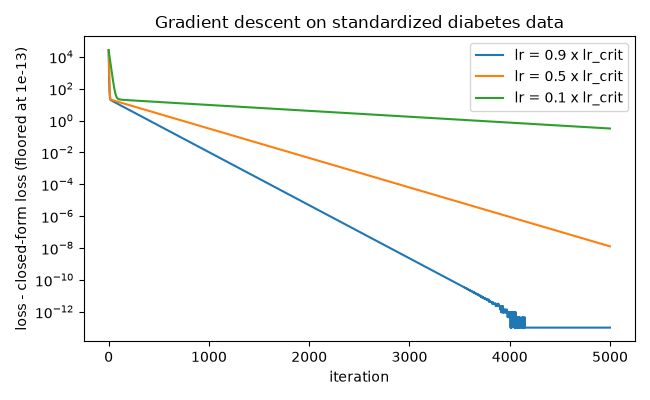

In [3]:
Xs = standardize(X)
Xb = lin.add_bias(Xs)
lam_max = np.linalg.eigvalsh(2.0 / len(y) * Xb.T @ Xb).max()
lr_crit = 2.0 / lam_max
w_cf = lin.fit_closed_form(Xs, y)
loss_cf = lin.mse(y, lin.predict(Xs, w_cf))
print(f"lambda_max(H) = {lam_max:.3f}  ->  stable only for lr < {lr_crit:.3f}")

gaps = {}
for frac in (0.9, 0.5, 0.1):
    w_gd, losses = lin.fit_gradient_descent(Xs, y, lr=frac * lr_crit, n_iter=5000)
    gaps[frac] = losses - loss_cf
    print(f"lr = {frac} * lr_crit: max |w_gd - w_closed| = {np.abs(w_gd - w_cf).max():.3e} | final loss gap = {gaps[frac][-1]:.3e}")
    if frac == 0.9:
        summary["gd_w"] = np.abs(w_gd - w_cf).max()

with np.errstate(all="ignore"):  # this run is meant to blow up
    _, bad = lin.fit_gradient_descent(Xs, y, lr=1.6 * lr_crit, n_iter=50)
print(f"lr = 1.6 * lr_crit: loss after 50 steps = {bad[-1]:.3e}  (started at {bad[0]:.3e}: diverged)")

fig, ax = plt.subplots(figsize=(6.5, 4))
for frac, gap in gaps.items():
    ax.semilogy(np.maximum(gap, 1e-13), label=f"lr = {frac} x lr_crit")
ax.set_xlabel("iteration")
ax.set_ylabel("loss - closed-form loss (floored at 1e-13)")
ax.set_title("Gradient descent on standardized diabetes data")
ax.legend()
fig.tight_layout()
fig.savefig("figures/loss-curve.png", dpi=130)
plt.show()

## 2. Logistic regression on `load_breast_cancer` (569 samples, 30 features)

scikit-learn minimizes `C * sum(loss_i) + 0.5 * ||w||^2` (intercept not penalized). Dividing by `C * n` gives our objective `mean(loss) + 0.5 * l2 * ||w||^2` with `l2 = 1 / (C * n)`. We use `C = 1`. scikit-learn is run with a very tight tolerance so it is a fair reference. Gradient descent is slower than L-BFGS, so the table shows how the match depends on the iteration budget.

In [4]:
bc = load_breast_cancer()
Xc, yc = standardize(bc.data), bc.target.astype(float)
n = len(yc)
l2 = 1.0 / n  # corresponds to sklearn C = 1

ref = LogisticRegression(C=1.0, tol=1e-12, max_iter=100000).fit(Xc, yc)
w_ref = np.r_[ref.intercept_, ref.coef_.ravel()]
p_ref = ref.predict_proba(Xc)[:, 1]

Xbc = lin.add_bias(Xc)
L = np.linalg.eigvalsh(Xbc.T @ Xbc / (4 * n)).max()  # smoothness constant (docs/02)
lr = 1.0 / (L + l2)
print(f"smoothness L = {L:.3f}, learning rate used = {lr:.3f}")

print(f"{'iterations':>10} | {'max |w - w_sk|':>15} | {'max |p - p_sk|':>15} | labels equal | accuracy (ours / sklearn)")
for n_iter in (2000, 20000, 100000):
    w = lg.fit(Xc, yc, lr=lr, n_iter=n_iter, l2=l2)
    p = lg.predict_proba(Xc, w)
    dw, dp = np.abs(w - w_ref).max(), np.abs(p - p_ref).max()
    same = (lg.predict(Xc, w) == ref.predict(Xc)).mean()
    acc, acc_ref = (lg.predict(Xc, w) == yc).mean(), (ref.predict(Xc) == yc).mean()
    print(f"{n_iter:>10} | {dw:>15.3e} | {dp:>15.3e} | {same:>12.4f} | {acc:.4f} / {acc_ref:.4f}")
    if n_iter == 20000:
        summary["lg_w"], summary["lg_p"], summary["lg_acc"] = dw, dp, acc

smoothness L = 3.320, learning rate used = 0.301
iterations |  max |w - w_sk| |  max |p - p_sk| | labels equal | accuracy (ours / sklearn)
      2000 |       9.081e-02 |       2.393e-02 |       1.0000 | 0.9877 / 0.9877
     20000 |       2.145e-06 |       5.618e-07 |       1.0000 | 0.9877 / 0.9877
    100000 |       1.128e-06 |       4.508e-07 |       1.0000 | 0.9877 / 0.9877


two-feature weights  ours: [ 0.699602 -3.337338 -0.877128]  sklearn: [ 0.699602 -3.337338 -0.877128]


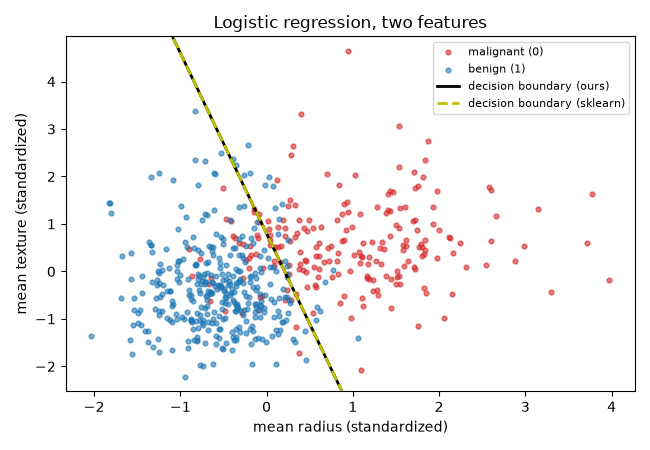

In [5]:
# Decision boundary on two features (mean radius, mean texture), for the figure
X2 = standardize(bc.data[:, :2])
l2_2 = 1.0 / n
Xb2 = lin.add_bias(X2)
L2 = np.linalg.eigvalsh(Xb2.T @ Xb2 / (4 * n)).max()
w2 = lg.fit(X2, yc, lr=1.0 / (L2 + l2_2), n_iter=20000, l2=l2_2)
ref2 = LogisticRegression(C=1.0, tol=1e-12, max_iter=100000).fit(X2, yc)
w2_ref = np.r_[ref2.intercept_, ref2.coef_.ravel()]
print("two-feature weights  ours:", np.round(w2, 6), " sklearn:", np.round(w2_ref, 6))

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for label, name, color in ((0, "malignant (0)", "tab:red"), (1, "benign (1)", "tab:blue")):
    m = yc == label
    ax.scatter(X2[m, 0], X2[m, 1], s=12, alpha=0.6, color=color, label=name)
xs = np.linspace(X2[:, 0].min(), X2[:, 0].max(), 100)
ax.plot(xs, -(w2[0] + w2[1] * xs) / w2[2], "k-", lw=2, label="decision boundary (ours)")
ax.plot(xs, -(w2_ref[0] + w2_ref[1] * xs) / w2_ref[2], "y--", lw=2, label="decision boundary (sklearn)")
ax.set_ylim(X2[:, 1].min() - 0.3, X2[:, 1].max() + 0.3)
ax.set_xlabel("mean radius (standardized)")
ax.set_ylabel("mean texture (standardized)")
ax.set_title("Logistic regression, two features")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("figures/logistic-boundary.png", dpi=130)
plt.show()

## 3. PCA on `load_wine` (178 samples, 13 features, standardized)

Components are defined only up to sign, so they are compared with `|cos|` between matching components, and scores by absolute value.

max |explained variance diff| = 0.00e+00
max | |cos(component_i, sklearn component_i)| - 1 | = 1.33e-15
max | |scores| diff | = 8.88e-16
explained variance ratio, first 5: [0.362  0.1921 0.1112 0.0707 0.0656] | cumulative: [0.362  0.5541 0.6653 0.736  0.8016]


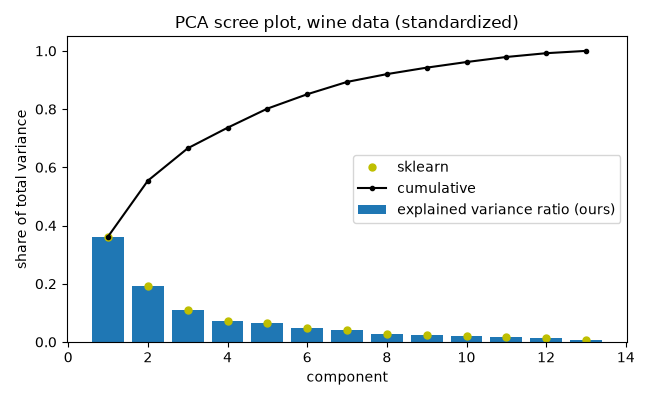

In [6]:
wine = load_wine()
Xw = standardize(wine.data)
mean, comps, var = mypca.fit(Xw, 13)
ref = PCA(n_components=13, svd_solver="full").fit(Xw)

d_var = np.abs(var - ref.explained_variance_).max()
d_cos = max(abs(abs(comps[i] @ ref.components_[i]) - 1) for i in range(13))
d_scores = np.abs(np.abs(mypca.transform(Xw, mean, comps)) - np.abs(ref.transform(Xw))).max()
print(f"max |explained variance diff| = {d_var:.2e}")
print(f"max | |cos(component_i, sklearn component_i)| - 1 | = {d_cos:.2e}")
print(f"max | |scores| diff | = {d_scores:.2e}")
summary["pca_var"], summary["pca_cos"], summary["pca_scores"] = d_var, d_cos, d_scores

ratio = var / var.sum()
print("explained variance ratio, first 5:", np.round(ratio[:5], 4), "| cumulative:", np.round(np.cumsum(ratio)[:5], 4))

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(range(1, 14), ratio, color="tab:blue", label="explained variance ratio (ours)")
ax.plot(range(1, 14), ref.explained_variance_ratio_, "yo", ms=5, label="sklearn")
ax.plot(range(1, 14), np.cumsum(ratio), "k.-", label="cumulative")
ax.set_xlabel("component")
ax.set_ylabel("share of total variance")
ax.set_title("PCA scree plot, wine data (standardized)")
ax.legend()
fig.tight_layout()
fig.savefig("figures/pca-scree.png", dpi=130)
plt.show()

## Summary

Everything compared above, in one table (values come from the cells above).

In [7]:
rows = [
    ("Linear regression (OLS), diabetes", "max |prediction diff|", summary["ols_pred"]),
    ("Linear regression (OLS), diabetes", "|MSE diff|", summary["ols_mse"]),
    ("Ridge alpha=1, diabetes", "max |prediction diff|", summary["ridge_1.0"]),
    ("Ridge alpha=10, diabetes", "max |prediction diff|", summary["ridge_10.0"]),
    ("Gradient descent (0.9 x lr_crit, 5000 it), diabetes std.", "max |weight diff| vs closed form", summary["gd_w"]),
    ("Logistic regression (20000 it), breast cancer", "max |weight diff| vs sklearn", summary["lg_w"]),
    ("Logistic regression (20000 it), breast cancer", "max |probability diff| vs sklearn", summary["lg_p"]),
    ("PCA, wine", "max |explained variance diff|", summary["pca_var"]),
    ("PCA, wine", "max | |cos| - 1 | of components", summary["pca_cos"]),
    ("PCA, wine", "max | |scores| diff |", summary["pca_scores"]),
]
for name, what, value in rows:
    print(f"{name:<58} {what:<36} {value:.2e}")

Linear regression (OLS), diabetes                          max |prediction diff|                7.67e-13
Linear regression (OLS), diabetes                          |MSE diff|                           4.55e-13
Ridge alpha=1, diabetes                                    max |prediction diff|                1.14e-13
Ridge alpha=10, diabetes                                   max |prediction diff|                8.53e-14
Gradient descent (0.9 x lr_crit, 5000 it), diabetes std.   max |weight diff| vs closed form     1.69e-07
Logistic regression (20000 it), breast cancer              max |weight diff| vs sklearn         2.14e-06
Logistic regression (20000 it), breast cancer              max |probability diff| vs sklearn    5.62e-07
PCA, wine                                                  max |explained variance diff|        0.00e+00
PCA, wine                                                  max | |cos| - 1 | of components      1.33e-15
PCA, wine                                              